In [2]:
# ==========================================================
# Cell 1 — Imports and configuration
# Notebook 5: Dataset, Descriptor and Dependency Analysis
# ==========================================================

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from scipy.stats import pearsonr, spearmanr

from rdkit import Chem, DataStructs
from rdkit.Chem import Descriptors, rdMolDescriptors
from rdkit.Chem import rdFingerprintGenerator

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


# ----------------------------------------------------------
# Reproducibility / numerical constants
# ----------------------------------------------------------

RANDOM_STATE = 42
EPSILON = 1e-6


# ----------------------------------------------------------
# Plot configuration
# ----------------------------------------------------------

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 11


# ----------------------------------------------------------
# Output folders
# ----------------------------------------------------------

FIG_DIR = Path("../outputs/figures")
METRICS_DIR = Path("../outputs/metrics")

FIG_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

print("Notebook 5 setup complete.")

Notebook 5 setup complete.


In [3]:
# ==========================================================
# Cell 2 — Load OEDB dataset
# ==========================================================

DATA_PATH_CANDIDATES = [
    Path("../data/raw/oedb_electrolytes_v2026_05_11.csv"),
    Path("data/raw/oedb_electrolytes_v2026_05_11.csv"),
    Path("/mnt/data/oedb-electrolytes-v2026-05-11 (2).csv"),
]

DATA_PATH = None

for path in DATA_PATH_CANDIDATES:
    if path.exists():
        DATA_PATH = path
        break

if DATA_PATH is None:
    raise FileNotFoundError(
        "OEDB CSV could not be found. Check DATA_PATH_CANDIDATES."
    )

raw_df = pd.read_csv(DATA_PATH)

print("Data path:", DATA_PATH)
print("Raw dataset shape:", raw_df.shape)

display(raw_df.head())

Data path: ..\data\raw\oedb_electrolytes_v2026_05_11.csv
Raw dataset shape: (5616, 20)


,ID,exp-ID,Cation,Anion,Solvent,Concentration (mol/kg),Ionic Conductivity (mS/cm),Viscosity (mPa·s),Cation's Diffusivity (m²/s),Anion's Diffusivity (m²/s),Solvent's Diffusivity (m²/s),Coordination (Cation←Anion),Coordination (Cation ← Solvent),Density (g/cm³),Anion SMILES,Solvent SMILES,Anion PubChem CID,Solvent PubChem CID,x,y
0,1,NaN,K,BETI,AN,0.5,18.348073,0.320151,1.280000e-09,1.090000e-09,2.510000e-09,0.177195,6.482342,0.850743,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-60.781920,-21.211819
1,2,NaN,K,BETI,AN,1.0,40.029239,0.778737,1.230000e-09,7.410000e-10,2.110000e-09,0.332376,6.218885,0.933113,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-60.421020,-20.695742
2,3,NaN,K,BETI,AN,1.5,28.589258,0.834437,1.090000e-09,6.840000e-10,1.830000e-09,0.473627,6.034723,1.000746,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-59.876976,-19.905375
3,4,NaN,K,BETI,AN,2.0,28.614872,1.298528,7.870000e-10,5.880000e-10,1.470000e-09,0.590422,5.873371,1.066779,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-59.369880,-19.195618
4,5,NaN,K,BETI,AN,2.5,37.791487,1.086047,6.760000e-10,4.690000e-10,1.200000e-09,0.741233,5.662183,1.120867,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-58.683660,-18.369247


In [4]:
# ==========================================================
# Cell 3 — Clean column names and create transformed variables
# ==========================================================

rename_map = {
    "ID": "id",
    "exp-ID": "exp_id",
    "Cation": "cation",
    "Anion": "anion",
    "Solvent": "solvent",

    "Concentration (mol/kg)": "concentration_mol_kg",
    "Ionic Conductivity (mS/cm)": "ionic_conductivity_ms_cm",
    "Viscosity (mPa·s)": "viscosity_mpa_s",

    "Cation's Diffusivity (m²/s)": "cation_diffusivity_m2_s",
    "Anion's Diffusivity (m²/s)": "anion_diffusivity_m2_s",
    "Solvent's Diffusivity (m²/s)": "solvent_diffusivity_m2_s",

    "Coordination (Cation←Anion)": "coordination_cation_anion",
    "Coordination (Cation ← Solvent)": "coordination_cation_solvent",

    "Density (g/cm³)": "density_g_cm3",

    "Anion SMILES": "anion_smiles",
    "Solvent SMILES": "solvent_smiles",

    "Anion PubChem CID": "anion_pubchem_cid",
    "Solvent PubChem CID": "solvent_pubchem_cid",

    "x": "tsne_x",
    "y": "tsne_y",
}

df = raw_df.rename(columns=rename_map).copy()


# Only conductivity-missing rows are excluded from conductivity analysis.
data = (
    df
    .dropna(subset=["ionic_conductivity_ms_cm"])
    .reset_index(drop=True)
    .copy()
)


# ----------------------------------------------------------
# Log transformation of strongly skewed transport properties
# ----------------------------------------------------------

data["log_conductivity"] = np.log10(
    data["ionic_conductivity_ms_cm"] + EPSILON
)

positive_log_columns = [
    "viscosity_mpa_s",
    "cation_diffusivity_m2_s",
    "anion_diffusivity_m2_s",
    "solvent_diffusivity_m2_s",
]

for col in positive_log_columns:

    data[f"log10_{col}"] = np.where(
        data[col] > 0,
        np.log10(data[col]),
        np.nan
    )


print("Raw rows:", len(df))
print("Conductivity-usable rows:", len(data))
print("Rows missing conductivity:", len(df) - len(data))

display(data.head())

Raw rows: 5616
Conductivity-usable rows: 5595
Rows missing conductivity: 21


,id,exp_id,cation,anion,solvent,concentration_mol_kg,ionic_conductivity_ms_cm,viscosity_mpa_s,cation_diffusivity_m2_s,anion_diffusivity_m2_s,...,solvent_smiles,anion_pubchem_cid,solvent_pubchem_cid,tsne_x,tsne_y,log_conductivity,log10_viscosity_mpa_s,log10_cation_diffusivity_m2_s,log10_anion_diffusivity_m2_s,log10_solvent_diffusivity_m2_s
0,1,NaN,K,BETI,AN,0.5,18.348073,0.320151,1.280000e-09,1.090000e-09,...,CC#N,4067273,6342,-60.781920,-21.211819,1.263590,-0.494646,-8.892790,-8.962574,-8.600326
1,2,NaN,K,BETI,AN,1.0,40.029239,0.778737,1.230000e-09,7.410000e-10,...,CC#N,4067273,6342,-60.421020,-20.695742,1.602377,-0.108609,-8.910095,-9.130182,-8.675718
2,3,NaN,K,BETI,AN,1.5,28.589258,0.834437,1.090000e-09,6.840000e-10,...,CC#N,4067273,6342,-59.876976,-19.905375,1.456203,-0.078607,-8.962574,-9.164944,-8.737549
3,4,NaN,K,BETI,AN,2.0,28.614872,1.298528,7.870000e-10,5.880000e-10,...,CC#N,4067273,6342,-59.369880,-19.195618,1.456592,0.113451,-9.104025,-9.230623,-8.832683
4,5,NaN,K,BETI,AN,2.5,37.791487,1.086047,6.760000e-10,4.690000e-10,...,CC#N,4067273,6342,-58.683660,-18.369247,1.577394,0.035849,-9.170053,-9.328827,-8.920819


In [5]:
# ==========================================================
# Cell 4 — Data integrity and chemical coverage
# ==========================================================

missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": 100 * df.isna().mean(),
}).sort_values(
    "missing_percent",
    ascending=False
)

print("Missing-value summary:")
display(missing_summary)


# ----------------------------------------------------------
# Chemical coverage
# ----------------------------------------------------------

n_cations = df["cation"].nunique()
n_anions = df["anion"].nunique()
n_solvents = df["solvent"].nunique()
n_concentrations = df["concentration_mol_kg"].nunique()

expected_full_grid = (
    n_cations
    * n_anions
    * n_solvents
    * n_concentrations
)

coverage_summary = pd.DataFrame([
    {"Quantity": "Total formulations", "Value": len(df)},
    {"Quantity": "Conductivity-usable formulations", "Value": len(data)},
    {"Quantity": "Unique cations", "Value": n_cations},
    {"Quantity": "Unique anions", "Value": n_anions},
    {"Quantity": "Unique solvents", "Value": n_solvents},
    {
        "Quantity": "Unique concentration levels",
        "Value": n_concentrations
    },
    {
        "Quantity": "Expected factorial combinations",
        "Value": expected_full_grid
    },
])

display(coverage_summary)


print("Cations:")
print(sorted(df["cation"].unique()))

print("\nAnions:")
print(sorted(df["anion"].unique()))

print("\nSolvents:")
print(sorted(df["solvent"].unique()))

print("\nConcentrations:")
print(sorted(df["concentration_mol_kg"].unique()))


coverage_summary.to_csv(
    METRICS_DIR / "notebook5_dataset_coverage.csv",
    index=False
)

missing_summary.to_csv(
    METRICS_DIR / "notebook5_missing_value_summary.csv"
)

Missing-value summary:


,missing_count,missing_percent
exp_id,5216,92.877493
ionic_conductivity_ms_cm,21,0.373932
cation_diffusivity_m2_s,8,0.142450
anion_diffusivity_m2_s,8,0.142450
anion,0,0.000000
cation,0,0.000000
id,0,0.000000
solvent,0,0.000000
viscosity_mpa_s,0,0.000000
concentration_mol_kg,0,0.000000


,Quantity,Value
0,Total formulations,5616
1,Conductivity-usable formulations,5595
2,Unique cations,3
3,Unique anions,9
4,Unique solvents,26
5,Unique concentration levels,8
6,Expected factorial combinations,5616


Cations:
['K', 'Li', 'Na']

Anions:
['BETI', 'BF4', 'ClO4', 'DFOB', 'FSI', 'OTf', 'PF6', 'TFA', 'TFSI']

Solvents:
['AN', 'Ac', 'Ac2O', 'BC', 'DEC', 'DMC', 'DMI', 'DMSO', 'EA', 'EB', 'EC', 'EMC', 'EP', 'FAN', 'FEA', 'FEC', 'FEMC', 'GBL', 'GN', 'MA', 'MB', 'MP', 'PC', 'SN', 'TEP', 'TMP']

Concentrations:
[np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0)]


In [6]:
# ==========================================================
# Cell 5 — Physicochemical property distributions
# ==========================================================

property_columns = [
    "ionic_conductivity_ms_cm",
    "log_conductivity",
    "viscosity_mpa_s",
    "cation_diffusivity_m2_s",
    "anion_diffusivity_m2_s",
    "solvent_diffusivity_m2_s",
    "coordination_cation_anion",
    "coordination_cation_solvent",
    "density_g_cm3",
    "concentration_mol_kg",
]

property_summary = (
    data[property_columns]
    .describe(
        percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
    )
    .T
)

property_summary["skewness"] = (
    data[property_columns]
    .skew(numeric_only=True)
)

display(property_summary)

property_summary.to_csv(
    METRICS_DIR / "notebook5_property_distribution_summary.csv"
)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skewness
ionic_conductivity_ms_cm,5595.0,6.135086e+00,1.275039e+01,1.257100e-04,6.748703e-03,2.959045e-02,4.047813e-01,1.641149e+00,5.078750e+00,3.273050e+01,6.555474e+01,1.271093e+02,3.964626
log_conductivity,5595.0,1.269326e-01,8.738429e-01,-3.897189e+00,-2.170741e+00,-1.528834e+00,-3.927786e-01,2.151482e-01,7.057569e-01,1.514951e+00,1.816604e+00,2.104177e+00,-0.489224
viscosity_mpa_s,5595.0,1.672511e+01,3.393505e+01,1.624182e-01,4.117221e-01,8.050812e-01,2.803769e+00,7.376878e+00,1.716275e+01,4.870314e+01,1.869148e+02,5.149166e+02,5.899563
cation_diffusivity_m2_s,5587.0,1.471538e-10,2.608264e-10,3.780000e-14,1.067200e-13,7.060000e-13,1.200000e-11,4.830000e-11,1.460000e-10,7.220000e-10,1.321400e-09,1.870000e-09,0.000000
anion_diffusivity_m2_s,5587.0,1.528800e-10,2.723035e-10,4.920000e-14,8.140000e-14,7.491000e-13,1.250000e-11,5.250000e-11,1.560000e-10,7.220000e-10,1.392800e-09,2.430000e-09,0.000000
solvent_diffusivity_m2_s,5595.0,4.181112e-10,6.392605e-10,4.320000e-14,7.555200e-14,1.490000e-12,3.210000e-11,1.500000e-10,4.995000e-10,1.890000e-09,2.920600e-09,4.370000e-09,0.000000
coordination_cation_anion,5595.0,2.779833e+00,2.197163e+00,1.086960e-04,8.658472e-02,3.328390e-01,1.309246e+00,2.304713e+00,3.614628e+00,7.103958e+00,1.123319e+01,1.379831e+01,1.866031
coordination_cation_solvent,5595.0,5.480803e+00,3.605031e+00,2.323620e-01,1.035726e+00,1.693502e+00,3.119165e+00,4.514899e+00,6.854996e+00,1.246996e+01,1.751321e+01,4.568165e+01,2.197031
density_g_cm3,5595.0,1.217742e+00,1.811595e-01,7.612277e-01,8.148959e-01,9.161471e-01,1.105766e+00,1.208602e+00,1.332533e+00,1.535858e+00,1.655299e+00,1.781734e+00,0.164779
concentration_mol_kg,5595.0,2.253172e+00,1.145410e+00,5.000000e-01,5.000000e-01,5.000000e-01,1.500000e+00,2.500000e+00,3.500000e+00,4.000000e+00,4.000000e+00,4.000000e+00,-0.003048


,factor,eta_squared
2,solvent,0.636403
1,anion,0.049862
0,cation,0.020795
3,concentration_mol_kg,0.010973


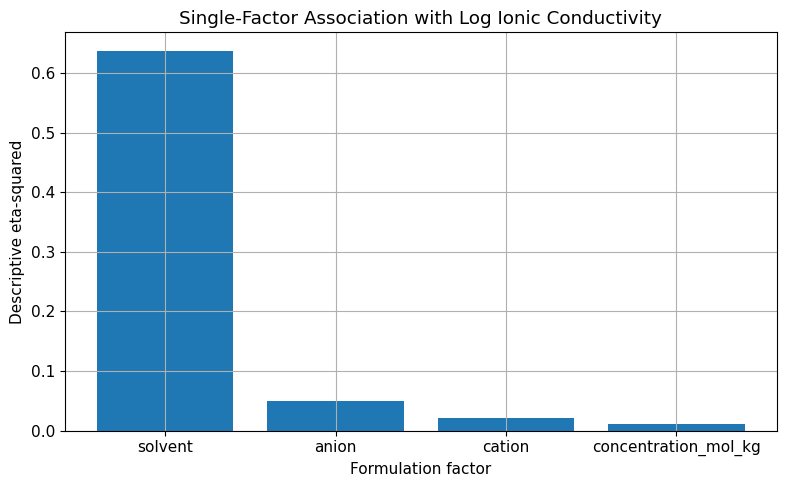

In [7]:
# ==========================================================
# Cell 6 — Main-factor effect size on log conductivity
# ==========================================================

def eta_squared_one_factor(frame, factor, target):

    temp = (
        frame[[factor, target]]
        .dropna()
        .copy()
    )

    grand_mean = temp[target].mean()

    ss_total = (
        (temp[target] - grand_mean) ** 2
    ).sum()

    grouped = (
        temp
        .groupby(factor)[target]
        .agg(["count", "mean"])
    )

    ss_between = (
        grouped["count"]
        * (grouped["mean"] - grand_mean) ** 2
    ).sum()

    if ss_total == 0:
        return np.nan

    return ss_between / ss_total


factors = [
    "cation",
    "anion",
    "solvent",
    "concentration_mol_kg",
]

effect_rows = []

for factor in factors:

    effect_rows.append({
        "factor": factor,
        "eta_squared": eta_squared_one_factor(
            data,
            factor,
            "log_conductivity"
        )
    })

factor_effects = (
    pd.DataFrame(effect_rows)
    .sort_values(
        "eta_squared",
        ascending=False
    )
)

display(factor_effects)

factor_effects.to_csv(
    METRICS_DIR / "notebook5_main_factor_effect_sizes.csv",
    index=False
)


plt.figure(figsize=(8, 5))

plt.bar(
    factor_effects["factor"],
    factor_effects["eta_squared"]
)

plt.ylabel("Descriptive eta-squared")
plt.xlabel("Formulation factor")
plt.title(
    "Single-Factor Association with Log Ionic Conductivity"
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "notebook5_main_factor_effect_sizes.png",
    dpi=300
)

plt.show()

In [8]:
# ==========================================================
# Cell 7 — Global Pearson and Spearman dependency analysis
# ==========================================================

dependency_columns = [
    "log_conductivity",

    "concentration_mol_kg",

    "log10_viscosity_mpa_s",

    "log10_cation_diffusivity_m2_s",
    "log10_anion_diffusivity_m2_s",
    "log10_solvent_diffusivity_m2_s",

    "coordination_cation_anion",
    "coordination_cation_solvent",

    "density_g_cm3",
]


pearson_corr = (
    data[dependency_columns]
    .corr(method="pearson")
)

spearman_corr = (
    data[dependency_columns]
    .corr(method="spearman")
)

print("Pearson correlation:")
display(pearson_corr.round(3))

print("Spearman correlation:")
display(spearman_corr.round(3))


pearson_corr.to_csv(
    METRICS_DIR / "notebook5_pearson_dependency_matrix.csv"
)

spearman_corr.to_csv(
    METRICS_DIR / "notebook5_spearman_dependency_matrix.csv"
)

Pearson correlation:


,log_conductivity,concentration_mol_kg,log10_viscosity_mpa_s,log10_cation_diffusivity_m2_s,log10_anion_diffusivity_m2_s,log10_solvent_diffusivity_m2_s,coordination_cation_anion,coordination_cation_solvent,density_g_cm3
log_conductivity,1.000,-0.054,-0.425,0.702,0.707,0.514,-0.283,0.148,-0.111
concentration_mol_kg,-0.054,1.000,0.381,-0.389,-0.404,-0.324,0.291,-0.318,0.400
log10_viscosity_mpa_s,-0.425,0.381,1.000,-0.889,-0.882,-0.947,-0.195,0.018,0.634
log10_cation_diffusivity_m2_s,0.702,-0.389,-0.889,1.000,0.996,0.931,-0.009,0.116,-0.499
log10_anion_diffusivity_m2_s,0.707,-0.404,-0.882,0.996,1.000,0.927,-0.024,0.123,-0.498
log10_solvent_diffusivity_m2_s,0.514,-0.324,-0.947,0.931,0.927,1.000,0.231,0.035,-0.501
coordination_cation_anion,-0.283,0.291,-0.195,-0.009,-0.024,0.231,1.000,-0.210,-0.035
coordination_cation_solvent,0.148,-0.318,0.018,0.116,0.123,0.035,-0.210,1.000,0.206
density_g_cm3,-0.111,0.400,0.634,-0.499,-0.498,-0.501,-0.035,0.206,1.000


Spearman correlation:


,log_conductivity,concentration_mol_kg,log10_viscosity_mpa_s,log10_cation_diffusivity_m2_s,log10_anion_diffusivity_m2_s,log10_solvent_diffusivity_m2_s,coordination_cation_anion,coordination_cation_solvent,density_g_cm3
log_conductivity,1.000,-0.103,-0.431,0.702,0.710,0.463,-0.267,0.254,-0.110
concentration_mol_kg,-0.103,1.000,0.410,-0.440,-0.464,-0.375,0.388,-0.302,0.415
log10_viscosity_mpa_s,-0.431,0.410,1.000,-0.887,-0.881,-0.984,-0.141,0.021,0.658
log10_cation_diffusivity_m2_s,0.702,-0.440,-0.887,1.000,0.995,0.896,-0.058,0.128,-0.548
log10_anion_diffusivity_m2_s,0.710,-0.464,-0.881,0.995,1.000,0.885,-0.091,0.134,-0.553
log10_solvent_diffusivity_m2_s,0.463,-0.375,-0.984,0.896,0.885,1.000,0.166,-0.022,-0.620
coordination_cation_anion,-0.267,0.388,-0.141,-0.058,-0.091,0.166,1.000,-0.204,-0.012
coordination_cation_solvent,0.254,-0.302,0.021,0.128,0.134,-0.022,-0.204,1.000,0.185
density_g_cm3,-0.110,0.415,0.658,-0.548,-0.553,-0.620,-0.012,0.185,1.000


In [9]:
# ==========================================================
# Cell 8 — Physical-property association with conductivity
# ==========================================================

candidate_predictors = [
    "concentration_mol_kg",

    "log10_viscosity_mpa_s",

    "log10_cation_diffusivity_m2_s",
    "log10_anion_diffusivity_m2_s",
    "log10_solvent_diffusivity_m2_s",

    "coordination_cation_anion",
    "coordination_cation_solvent",

    "density_g_cm3",
]


association_rows = []

for predictor in candidate_predictors:

    temp = (
        data[[predictor, "log_conductivity"]]
        .dropna()
    )

    x = temp[predictor].values
    y = temp["log_conductivity"].values

    if len(np.unique(x)) < 2:
        continue

    pearson_r, pearson_p = pearsonr(x, y)

    spearman_r, spearman_p = spearmanr(x, y)

    association_rows.append({
        "predictor": predictor,
        "n": len(temp),

        "pearson_r": pearson_r,
        "pearson_p": pearson_p,

        "spearman_rho": spearman_r,
        "spearman_p": spearman_p,
    })


conductivity_associations = (
    pd.DataFrame(association_rows)
    .sort_values(
        "spearman_rho",
        key=lambda s: s.abs(),
        ascending=False
    )
)

display(conductivity_associations)

conductivity_associations.to_csv(
    METRICS_DIR /
    "notebook5_global_property_conductivity_associations.csv",
    index=False
)

,predictor,n,pearson_r,pearson_p,spearman_rho,spearman_p
3,log10_anion_diffusivity_m2_s,5587,0.706615,0.000000e+00,0.709553,0.000000e+00
2,log10_cation_diffusivity_m2_s,5587,0.701501,0.000000e+00,0.701512,0.000000e+00
4,log10_solvent_diffusivity_m2_s,5595,0.514310,0.000000e+00,0.463404,5.782027e-296
1,log10_viscosity_mpa_s,5595,-0.424920,3.581710e-244,-0.431143,4.232643e-252
5,coordination_cation_anion,5595,-0.282644,2.861690e-103,-0.266603,1.139178e-91
6,coordination_cation_solvent,5595,0.148087,8.397981e-29,0.254020,4.090963e-83
7,density_g_cm3,5595,-0.111159,7.513211e-17,-0.109920,1.649515e-16
0,concentration_mol_kg,5595,-0.054472,4.569323e-05,-0.103395,8.978855e-15


In [10]:
# ==========================================================
# Cell 9 — Conditional property dependencies
# ==========================================================

def groupwise_spearman(
    frame,
    group_column,
    x_column,
    y_column="log_conductivity",
    min_samples=20
):

    rows = []

    for group_name, subset in frame.groupby(group_column):

        temp = (
            subset[[x_column, y_column]]
            .dropna()
        )

        if len(temp) < min_samples:
            continue

        if temp[x_column].nunique() < 2:
            continue

        rho, p_value = spearmanr(
            temp[x_column],
            temp[y_column]
        )

        rows.append({
            "grouping": group_column,
            "group": group_name,
            "x_variable": x_column,
            "n": len(temp),
            "spearman_rho": rho,
            "p_value": p_value,
        })

    return pd.DataFrame(rows)


conditional_properties = [
    "log10_viscosity_mpa_s",

    "log10_cation_diffusivity_m2_s",
    "log10_anion_diffusivity_m2_s",

    "coordination_cation_anion",
    "coordination_cation_solvent",

    "concentration_mol_kg",
]

grouping_variables = [
    "solvent",
    "anion",
    "cation",
]


conditional_results = []

for grouping in grouping_variables:

    for property_name in conditional_properties:

        result = groupwise_spearman(
            data,
            grouping,
            property_name
        )

        conditional_results.append(result)


conditional_correlations = pd.concat(
    conditional_results,
    ignore_index=True
)

display(conditional_correlations.head(20))

conditional_correlations.to_csv(
    METRICS_DIR /
    "notebook5_conditional_property_correlations.csv",
    index=False
)

# ----------------------------------------------------------
# How stable is each relationship across chemical groups?
# ----------------------------------------------------------

conditional_summary = (
    conditional_correlations
    .groupby(
        ["grouping", "x_variable"]
    )
    .agg(
        n_groups=("group", "nunique"),

        median_rho=(
            "spearman_rho",
            "median"
        ),

        minimum_rho=(
            "spearman_rho",
            "min"
        ),

        maximum_rho=(
            "spearman_rho",
            "max"
        ),

        fraction_positive=(
            "spearman_rho",
            lambda x: np.mean(x > 0)
        )
    )
    .reset_index()
)

display(conditional_summary)

conditional_summary.to_csv(
    METRICS_DIR /
    "notebook5_conditional_correlation_summary.csv",
    index=False
)

,grouping,group,x_variable,n,spearman_rho,p_value
0,solvent,AN,log10_viscosity_mpa_s,216,0.257087,1.329724e-04
1,solvent,Ac,log10_viscosity_mpa_s,216,0.258285,1.233762e-04
2,solvent,Ac2O,log10_viscosity_mpa_s,216,-0.336059,4.230912e-07
3,solvent,BC,log10_viscosity_mpa_s,216,-0.451041,3.198462e-12
4,solvent,DEC,log10_viscosity_mpa_s,214,0.673786,1.124215e-29
5,solvent,DMC,log10_viscosity_mpa_s,211,0.055191,4.251374e-01
6,solvent,DMI,log10_viscosity_mpa_s,216,-0.685923,2.250401e-31
7,solvent,DMSO,log10_viscosity_mpa_s,216,-0.380894,7.249286e-09
8,solvent,EA,log10_viscosity_mpa_s,213,0.593871,1.083300e-21
9,solvent,EB,log10_viscosity_mpa_s,215,0.268141,6.834813e-05


,grouping,x_variable,n_groups,median_rho,minimum_rho,maximum_rho,fraction_positive
0,anion,concentration_mol_kg,9,-0.058984,-0.371275,0.251279,0.222222
1,anion,coordination_cation_anion,9,-0.310049,-0.429875,0.095286,0.111111
2,anion,coordination_cation_solvent,9,0.219510,0.048427,0.313300,1.000000
3,anion,log10_anion_diffusivity_m2_s,9,0.800016,0.315467,0.918025,1.000000
4,anion,log10_cation_diffusivity_m2_s,9,0.800048,0.335823,0.929044,1.000000
5,anion,log10_viscosity_mpa_s,9,-0.545088,-0.857438,-0.124622,0.000000
6,cation,concentration_mol_kg,3,-0.121941,-0.247571,0.032820,0.333333
7,cation,coordination_cation_anion,3,-0.372124,-0.434759,-0.353874,0.000000
8,cation,coordination_cation_solvent,3,0.182174,0.065705,0.413597,1.000000
9,cation,log10_anion_diffusivity_m2_s,3,0.690508,0.685578,0.731386,1.000000


,concentration_mol_kg,n_samples,conductivity_mean,conductivity_median,conductivity_q25,conductivity_q75,viscosity_median,coordination_anion_mean,coordination_solvent_mean
0,0.5,695,4.795531,1.878668,0.399069,5.057792,2.891527,1.712956,7.533462
1,1.0,698,6.460730,2.434791,0.579516,6.273899,4.122156,2.074079,6.715300
2,1.5,699,7.026950,2.251536,0.634428,6.176857,5.578628,2.398065,6.074242
3,2.0,699,6.773451,2.017141,0.560229,5.884237,7.555761,2.686812,5.570332
4,2.5,700,7.238271,1.670061,0.472869,5.251345,9.491748,2.972533,5.104193
5,3.0,701,5.963014,1.370540,0.371733,4.374808,11.567894,3.237122,4.657085
6,3.5,701,5.474135,1.069558,0.280873,3.851112,13.865276,3.481376,4.271924
7,4.0,702,5.345598,0.876969,0.243986,3.689320,15.359619,3.661229,3.946342


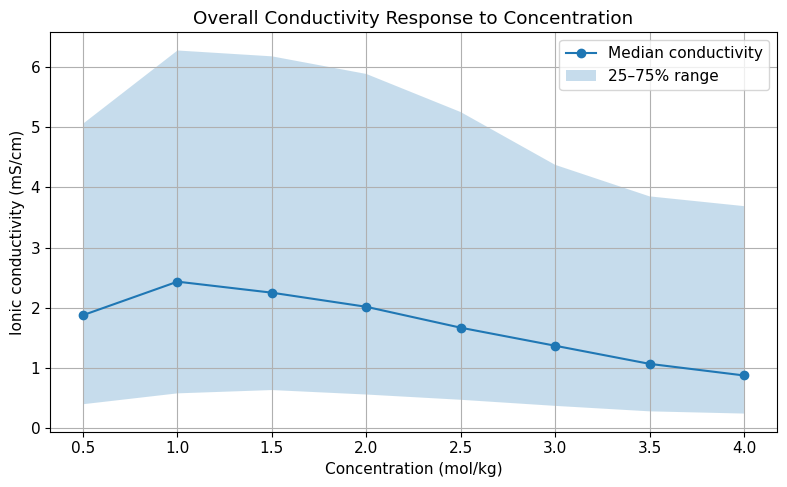

In [11]:
# ==========================================================
# Cell 10 — Concentration-response behaviour
# ==========================================================

concentration_summary = (
    data
    .groupby("concentration_mol_kg")
    .agg(

        n_samples=(
            "ionic_conductivity_ms_cm",
            "size"
        ),

        conductivity_mean=(
            "ionic_conductivity_ms_cm",
            "mean"
        ),

        conductivity_median=(
            "ionic_conductivity_ms_cm",
            "median"
        ),

        conductivity_q25=(
            "ionic_conductivity_ms_cm",
            lambda x: x.quantile(0.25)
        ),

        conductivity_q75=(
            "ionic_conductivity_ms_cm",
            lambda x: x.quantile(0.75)
        ),

        viscosity_median=(
            "viscosity_mpa_s",
            "median"
        ),

        coordination_anion_mean=(
            "coordination_cation_anion",
            "mean"
        ),

        coordination_solvent_mean=(
            "coordination_cation_solvent",
            "mean"
        ),
    )
    .reset_index()
)

display(concentration_summary)

concentration_summary.to_csv(
    METRICS_DIR /
    "notebook5_concentration_response_summary.csv",
    index=False
)

plt.figure(figsize=(8, 5))

x = concentration_summary[
    "concentration_mol_kg"
].values

median = concentration_summary[
    "conductivity_median"
].values

q25 = concentration_summary[
    "conductivity_q25"
].values

q75 = concentration_summary[
    "conductivity_q75"
].values


plt.plot(
    x,
    median,
    marker="o",
    label="Median conductivity"
)

plt.fill_between(
    x,
    q25,
    q75,
    alpha=0.25,
    label="25–75% range"
)

plt.xlabel("Concentration (mol/kg)")
plt.ylabel("Ionic conductivity (mS/cm)")

plt.title(
    "Overall Conductivity Response to Concentration"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIG_DIR /
    "notebook5_conductivity_vs_concentration.png",
    dpi=300
)

plt.show()

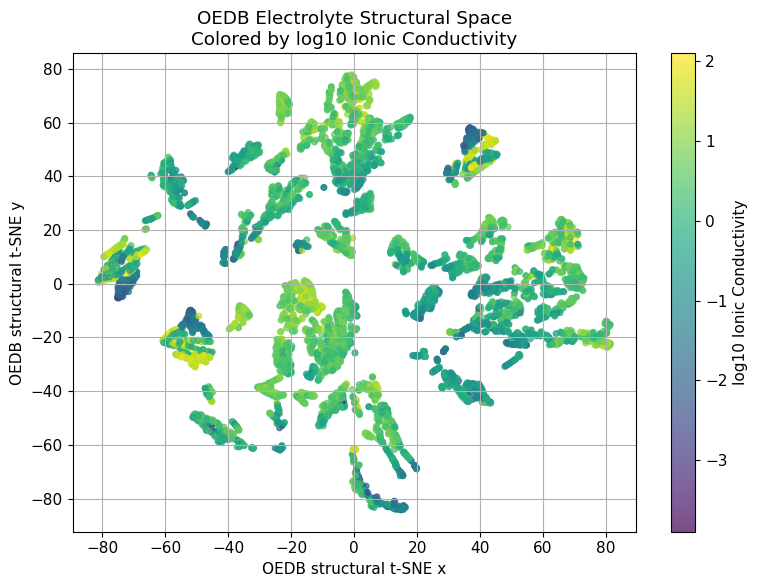

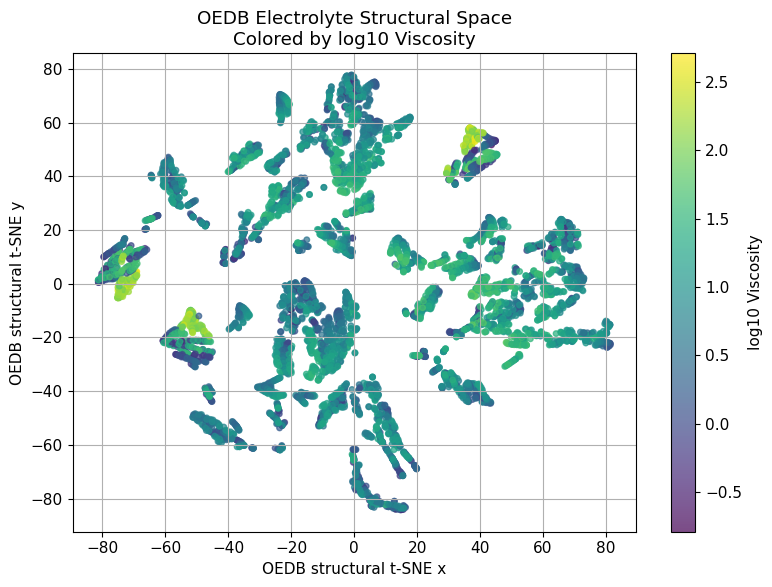

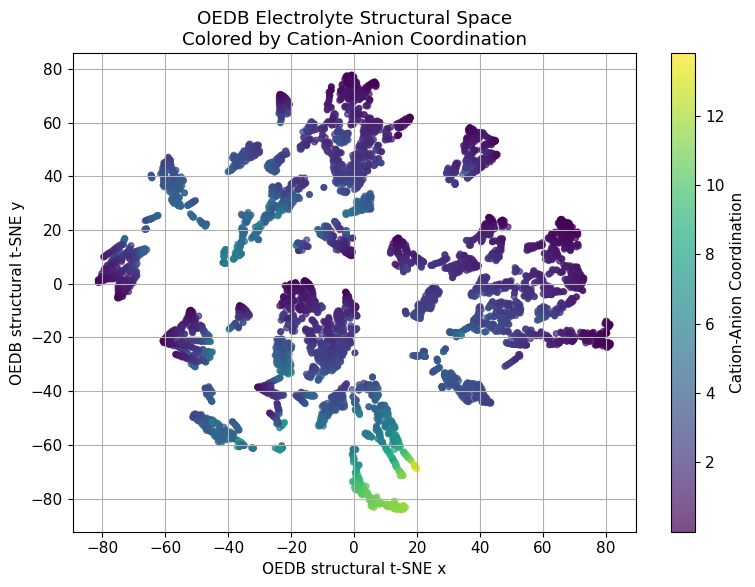

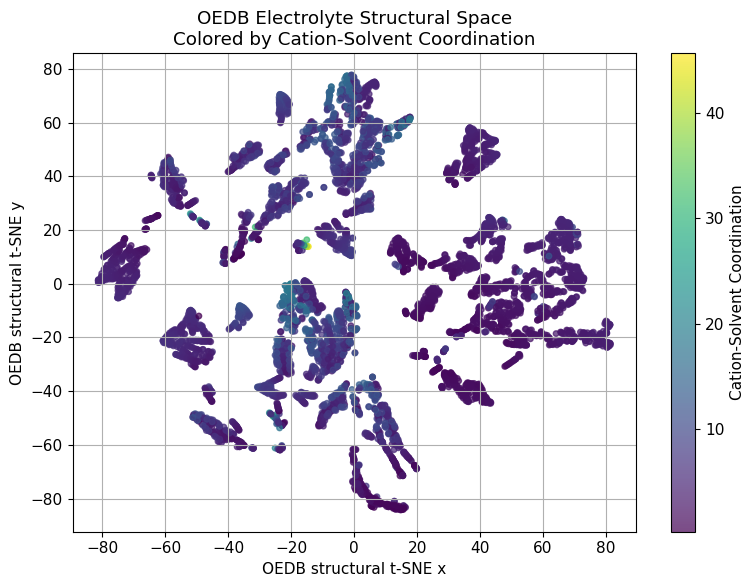

In [12]:
# ==========================================================
# Cell 11 — OEDB MD-derived structural map analysis
# ==========================================================

# IMPORTANT:
# tsne_x and tsne_y are used ONLY for scientific visualization.
# They are not used as predictive input features.

structure_data = (
    data[
        [
            "tsne_x",
            "tsne_y",
            "log_conductivity",
            "log10_viscosity_mpa_s",
            "coordination_cation_anion",
            "coordination_cation_solvent",
        ]
    ]
    .dropna(
        subset=["tsne_x", "tsne_y"]
    )
)


structure_properties = {

    "log_conductivity":
        "log10 Ionic Conductivity",

    "log10_viscosity_mpa_s":
        "log10 Viscosity",

    "coordination_cation_anion":
        "Cation-Anion Coordination",

    "coordination_cation_solvent":
        "Cation-Solvent Coordination",
}


for property_name, label in structure_properties.items():

    subset = structure_data.dropna(
        subset=[property_name]
    )

    plt.figure(figsize=(8, 6))

    scatter = plt.scatter(

        subset["tsne_x"],

        subset["tsne_y"],

        c=subset[property_name],

        s=16,

        alpha=0.7
    )

    plt.colorbar(
        scatter,
        label=label
    )

    plt.xlabel("OEDB structural t-SNE x")
    plt.ylabel("OEDB structural t-SNE y")

    plt.title(
        f"OEDB Electrolyte Structural Space\nColored by {label}"
    )

    plt.tight_layout()

    plt.savefig(
        FIG_DIR /
        f"notebook5_structure_space_{property_name}.png",
        dpi=300
    )

    plt.show()

In [13]:
# ==========================================================
# Cell 12 — RDKit molecular descriptor functions
# ==========================================================

DESCRIPTOR_NAMES = [

    "mol_wt",
    "exact_mol_wt",
    "tpsa",

    "num_h_acceptors",
    "num_h_donors",

    "num_rotatable_bonds",

    "ring_count",

    "heavy_atom_count",
    "num_hetero_atoms",

    "formal_charge",

    "num_f_atoms",
    "num_o_atoms",
    "num_n_atoms",
    "num_s_atoms",
]


def count_atom(mol, symbol):

    return sum(
        1
        for atom in mol.GetAtoms()
        if atom.GetSymbol() == symbol
    )


def smiles_to_descriptors(smiles):

    mol = Chem.MolFromSmiles(
        str(smiles)
    )

    if mol is None:

        raise ValueError(
            f"Invalid SMILES: {smiles}"
        )

    return {

        "mol_wt":
            Descriptors.MolWt(mol),

        "exact_mol_wt":
            Descriptors.ExactMolWt(mol),

        "tpsa":
            Descriptors.TPSA(mol),

        "num_h_acceptors":
            Descriptors.NumHAcceptors(mol),

        "num_h_donors":
            Descriptors.NumHDonors(mol),

        "num_rotatable_bonds":
            Descriptors.NumRotatableBonds(mol),

        "ring_count":
            rdMolDescriptors.CalcNumRings(mol),

        "heavy_atom_count":
            Descriptors.HeavyAtomCount(mol),

        "num_hetero_atoms":
            rdMolDescriptors.CalcNumHeteroatoms(mol),

        "formal_charge":
            Chem.GetFormalCharge(mol),

        "num_f_atoms":
            count_atom(mol, "F"),

        "num_o_atoms":
            count_atom(mol, "O"),

        "num_n_atoms":
            count_atom(mol, "N"),

        "num_s_atoms":
            count_atom(mol, "S"),
    }


def solvent_family_from_smiles(smiles):

    mol = Chem.MolFromSmiles(
        str(smiles)
    )

    if mol is None:
        return "Unknown"

    atoms = {
        atom.GetSymbol()
        for atom in mol.GetAtoms()
    }

    has_o = "O" in atoms
    has_n = "N" in atoms

    if has_o and has_n:
        return "O+N-based"

    if has_o:
        return "O-based"

    if has_n:
        return "N-based"

    return "Other"


print("Descriptor functions ready.")

Descriptor functions ready.


In [14]:
# ==========================================================
# Cell 13 — Unique molecular descriptor tables
# ==========================================================

# ----------------------------------------------------------
# Solvents
# ----------------------------------------------------------

solvent_table = (

    data[
        [
            "solvent",
            "solvent_smiles"
        ]
    ]

    .drop_duplicates()

    .sort_values("solvent")

    .reset_index(drop=True)
)


solvent_descriptors = pd.DataFrame(

    [
        smiles_to_descriptors(smiles)

        for smiles
        in solvent_table["solvent_smiles"]
    ]
)


solvent_table = pd.concat(

    [
        solvent_table,
        solvent_descriptors
    ],

    axis=1
)


solvent_table["solvent_family"] = (

    solvent_table["solvent_smiles"]

    .apply(
        solvent_family_from_smiles
    )
)


solvent_table["is_cyclic"] = (

    solvent_table["ring_count"] > 0
)


print(
    "Unique solvents:",
    len(solvent_table)
)

display(solvent_table)


# ----------------------------------------------------------
# Anions
# ----------------------------------------------------------

anion_table = (

    data[
        [
            "anion",
            "anion_smiles"
        ]
    ]

    .drop_duplicates()

    .sort_values("anion")

    .reset_index(drop=True)
)


anion_descriptors = pd.DataFrame(

    [
        smiles_to_descriptors(smiles)

        for smiles
        in anion_table["anion_smiles"]
    ]
)


anion_table = pd.concat(

    [
        anion_table,
        anion_descriptors
    ],

    axis=1
)


print(
    "Unique anions:",
    len(anion_table)
)

display(anion_table)


solvent_table.to_csv(
    METRICS_DIR /
    "notebook5_unique_solvent_descriptors.csv",
    index=False
)

anion_table.to_csv(
    METRICS_DIR /
    "notebook5_unique_anion_descriptors.csv",
    index=False
)

Unique solvents: 26


,solvent,solvent_smiles,mol_wt,exact_mol_wt,tpsa,num_h_acceptors,num_h_donors,num_rotatable_bonds,ring_count,heavy_atom_count,num_hetero_atoms,formal_charge,num_f_atoms,num_o_atoms,num_n_atoms,num_s_atoms,solvent_family,is_cyclic
0,AN,CC#N,41.053,41.026549,23.79,1,0,0,0,3,1,0,0,0,1,0,N-based,False
1,Ac,CC(=O)C,58.080,58.041865,17.07,1,0,0,0,4,1,0,0,1,0,0,O-based,False
2,Ac2O,CC(=O)OC(=O)C,102.089,102.031694,43.37,3,0,0,0,7,3,0,0,3,0,0,O-based,False
3,BC,C[C@H]1[C@@H](OC(=O)O1)C,116.116,116.047344,35.53,3,0,0,1,8,3,0,0,3,0,0,O-based,True
4,DEC,CCOC(=O)OCC,118.132,118.062994,35.53,3,0,2,0,8,3,0,0,3,0,0,O-based,False
5,DMC,COC(=O)OC,90.078,90.031694,35.53,3,0,0,0,6,3,0,0,3,0,0,O-based,False
6,DMI,CN1CCN(C1=O)C,114.148,114.079313,23.55,1,0,0,1,8,3,0,0,1,2,0,O+N-based,True
7,DMSO,CS(=O)C,78.136,78.013936,17.07,1,0,0,0,4,2,0,0,1,0,1,O-based,False
8,EA,CCOC(=O)C,88.106,88.052429,26.30,2,0,1,0,6,2,0,0,2,0,0,O-based,False
9,EB,CCCC(=O)OCC,116.160,116.083730,26.30,2,0,3,0,8,2,0,0,2,0,0,O-based,False


Unique anions: 9


,anion,anion_smiles,mol_wt,exact_mol_wt,tpsa,num_h_acceptors,num_h_donors,num_rotatable_bonds,ring_count,heavy_atom_count,num_hetero_atoms,formal_charge,num_f_atoms,num_o_atoms,num_n_atoms,num_s_atoms
0,BETI,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,380.161,379.911455,82.38,4,0,4,0,21,17,-1,10,4,1,2
1,BF4,[B-](F)(F)(F)F,86.804,87.003467,0.00,0,0,0,0,5,5,-1,4,0,0,0
2,ClO4,[O-]Cl(=O)(=O)=O,99.449,98.949060,92.24,4,0,0,0,5,5,-1,0,4,0,0
3,DFOB,[B-]1(OC(=O)C(=O)O1)(F)F,136.826,136.986319,52.60,4,0,0,1,9,7,-1,2,4,0,0
4,FSI,[N-](S(=O)(=O)F)S(=O)(=O)F,180.133,179.924229,82.38,4,0,2,0,9,9,-1,2,4,1,2
5,OTf,C(F)(F)(F)S(=O)(=O)[O-],149.069,148.952573,57.20,3,0,0,0,8,7,-1,3,3,0,1
6,PF6,F[P-](F)(F)(F)(F)F,144.962,144.964730,0.00,0,0,0,0,7,7,-1,6,0,0,0
7,TFA,C(=O)(C(F)(F)F)[O-],113.014,112.985587,40.13,2,0,0,0,7,5,-1,3,2,0,0
8,TFSI,C(F)(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(F)(F)F,280.147,279.917842,82.38,4,0,2,0,15,13,-1,6,4,1,2


In [15]:
# ==========================================================
# Cell 14 — Descriptor quality and redundancy analysis
# ==========================================================

descriptor_quality_rows = []


for descriptor in DESCRIPTOR_NAMES:

    values = solvent_table[
        descriptor
    ]

    descriptor_quality_rows.append({

        "descriptor": descriptor,

        "min": values.min(),

        "max": values.max(),

        "mean": values.mean(),

        "std": values.std(),

        "n_unique": values.nunique(),

        "constant_or_near_constant":
            (
                values.nunique() <= 1
                or
                values.std(ddof=0) < 1e-12
            )
    })


solvent_descriptor_quality = pd.DataFrame(
    descriptor_quality_rows
)

display(solvent_descriptor_quality)

solvent_descriptor_quality.to_csv(

    METRICS_DIR /
    "notebook5_solvent_descriptor_quality.csv",

    index=False
)

,descriptor,min,max,mean,std,n_unique,constant_or_near_constant
0,mol_wt,41.053000,182.156000,101.946885,29.289324,24,False
1,exact_mol_wt,41.026549,182.070796,101.888063,29.281456,22,False
2,tpsa,17.070000,47.580000,33.157692,9.188558,8,False
3,num_h_acceptors,1.000000,4.000000,2.384615,0.897861,4,False
4,num_h_donors,0.000000,0.000000,0.000000,0.000000,1,True
5,num_rotatable_bonds,0.000000,6.000000,1.115385,1.423430,5,False
6,ring_count,0.000000,1.000000,0.230769,0.429669,2,False
7,heavy_atom_count,3.000000,11.000000,6.807692,1.766788,7,False
8,num_hetero_atoms,1.000000,6.000000,2.807692,1.166850,6,False
9,formal_charge,0.000000,0.000000,0.000000,0.000000,1,True


In [16]:
# ==========================================================
# Cell 15 — Molecule-level response aggregation
# ==========================================================

# ----------------------------------------------------------
# Solvent-level response
# ----------------------------------------------------------

solvent_response = (

    data

    .groupby(
        [
            "solvent",
            "solvent_smiles"
        ]
    )

    .agg(

        n_formulations=(
            "id",
            "size"
        ),

        mean_log_conductivity=(
            "log_conductivity",
            "mean"
        ),

        median_log_conductivity=(
            "log_conductivity",
            "median"
        ),

        mean_conductivity=(
            "ionic_conductivity_ms_cm",
            "mean"
        ),

        max_conductivity=(
            "ionic_conductivity_ms_cm",
            "max"
        ),

        mean_log10_viscosity=(
            "log10_viscosity_mpa_s",
            "mean"
        ),

        mean_coord_cation_anion=(
            "coordination_cation_anion",
            "mean"
        ),

        mean_coord_cation_solvent=(
            "coordination_cation_solvent",
            "mean"
        ),

        mean_density=(
            "density_g_cm3",
            "mean"
        )
    )

    .reset_index()
)


solvent_analysis = (

    solvent_table

    .merge(

        solvent_response,

        on=[
            "solvent",
            "solvent_smiles"
        ],

        how="left"
    )
)


display(solvent_analysis)


# ----------------------------------------------------------
# Anion-level response
# ----------------------------------------------------------

anion_response = (

    data

    .groupby(
        [
            "anion",
            "anion_smiles"
        ]
    )

    .agg(

        n_formulations=(
            "id",
            "size"
        ),

        mean_log_conductivity=(
            "log_conductivity",
            "mean"
        ),

        mean_conductivity=(
            "ionic_conductivity_ms_cm",
            "mean"
        ),

        max_conductivity=(
            "ionic_conductivity_ms_cm",
            "max"
        ),

        mean_log10_viscosity=(
            "log10_viscosity_mpa_s",
            "mean"
        ),

        mean_coord_cation_anion=(
            "coordination_cation_anion",
            "mean"
        ),

        mean_coord_cation_solvent=(
            "coordination_cation_solvent",
            "mean"
        )
    )

    .reset_index()
)


anion_analysis = (

    anion_table

    .merge(

        anion_response,

        on=[
            "anion",
            "anion_smiles"
        ],

        how="left"
    )
)


display(anion_analysis)

,solvent,solvent_smiles,mol_wt,exact_mol_wt,tpsa,num_h_acceptors,num_h_donors,num_rotatable_bonds,ring_count,heavy_atom_count,...,is_cyclic,n_formulations,mean_log_conductivity,median_log_conductivity,mean_conductivity,max_conductivity,mean_log10_viscosity,mean_coord_cation_anion,mean_coord_cation_solvent,mean_density
0,AN,CC#N,41.053,41.026549,23.79,1,0,0,0,3,...,False,216,1.461275,1.535577,38.445499,127.109335,0.013519,1.731468,4.318741,0.939891
1,Ac,CC(=O)C,58.080,58.041865,17.07,1,0,0,0,4,...,False,216,1.410555,1.501102,34.234726,125.744140,-0.089784,1.896991,3.943915,0.927633
2,Ac2O,CC(=O)OC(=O)C,102.089,102.031694,43.37,3,0,0,0,7,...,False,216,0.725095,0.834563,7.881364,27.587752,0.818831,1.916543,7.229510,1.245847
3,BC,C[C@H]1[C@@H](OC(=O)O1)C,116.116,116.047344,35.53,3,0,0,1,8,...,True,216,-0.017417,0.051635,1.432196,5.974969,0.995460,3.602708,6.190919,1.262591
4,DEC,CCOC(=O)OCC,118.132,118.062994,35.53,3,0,2,0,8,...,False,214,-1.043192,-0.928906,0.229712,1.359127,0.626141,4.536023,7.508230,1.138509
5,DMC,COC(=O)OC,90.078,90.031694,35.53,3,0,0,0,6,...,False,211,0.169468,0.320875,2.697706,12.721972,0.700033,3.005445,6.465140,1.250430
6,DMI,CN1CCN(C1=O)C,114.148,114.079313,23.55,1,0,0,1,8,...,True,216,-0.103460,-0.028871,1.184645,4.560788,1.227966,2.084885,3.418386,1.232529
7,DMSO,CS(=O)C,78.136,78.013936,17.07,1,0,0,0,4,...,False,216,1.071558,1.149953,14.559065,44.684471,0.592242,1.219385,4.038864,1.230336
8,EA,CCOC(=O)C,88.106,88.052429,26.30,2,0,1,0,6,...,False,213,-0.283235,-0.034588,2.289190,15.602248,0.190962,4.263730,3.593990,1.051362
9,EB,CCCC(=O)OCC,116.160,116.083730,26.30,2,0,3,0,8,...,False,215,-0.221467,-0.055424,1.367595,7.197767,0.581492,3.478404,4.284154,1.034138


,anion,anion_smiles,mol_wt,exact_mol_wt,tpsa,num_h_acceptors,num_h_donors,num_rotatable_bonds,ring_count,heavy_atom_count,...,num_o_atoms,num_n_atoms,num_s_atoms,n_formulations,mean_log_conductivity,mean_conductivity,max_conductivity,mean_log10_viscosity,mean_coord_cation_anion,mean_coord_cation_solvent
0,BETI,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,380.161,379.911455,82.38,4,0,4,0,21,...,4,1,2,624,0.114525,5.229392,69.069201,1.014467,1.211835,6.777473
1,BF4,[B-](F)(F)(F)F,86.804,87.003467,0.00,0,0,0,0,5,...,0,0,0,620,0.000478,5.400813,75.175561,0.667366,4.880876,3.598204
2,ClO4,[O-]Cl(=O)(=O)=O,99.449,98.949060,92.24,4,0,0,0,5,...,4,0,0,621,0.122698,7.062447,116.550038,0.823532,3.270175,5.258968
3,DFOB,[B-]1(OC(=O)C(=O)O1)(F)F,136.826,136.986319,52.60,4,0,0,1,9,...,4,0,0,624,0.232076,6.188996,74.043938,0.862477,2.754625,5.568775
4,FSI,[N-](S(=O)(=O)F)S(=O)(=O)F,180.133,179.924229,82.38,4,0,2,0,9,...,4,1,2,624,0.334358,8.255170,127.109335,0.951100,1.832839,6.516320
5,OTf,C(F)(F)(F)S(=O)(=O)[O-],149.069,148.952573,57.20,3,0,0,0,8,...,3,0,1,620,-0.004185,4.399217,66.676128,0.825128,2.568033,5.218955
6,PF6,F[P-](F)(F)(F)(F)F,144.962,144.964730,0.00,0,0,0,0,7,...,0,0,0,623,0.400387,10.347307,125.744140,0.819496,3.378075,5.938773
7,TFA,C(=O)(C(F)(F)F)[O-],113.014,112.985587,40.13,2,0,0,0,7,...,2,0,0,615,-0.288560,1.578858,22.550213,0.632839,3.732789,3.654678
8,TFSI,C(F)(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(F)(F)F,280.147,279.917842,82.38,4,0,2,0,15,...,4,1,2,624,0.223390,6.683232,112.480881,0.997134,1.418418,6.754668


In [17]:
# ==========================================================
# Cell 16 — Descriptor-property association analysis
# ==========================================================

def benjamini_hochberg(p_values):

    p_values = np.asarray(
        p_values,
        dtype=float
    )

    n = len(p_values)

    order = np.argsort(p_values)

    ranked = p_values[order]

    adjusted = (
        ranked
        * n
        / np.arange(1, n + 1)
    )

    adjusted = np.minimum.accumulate(
        adjusted[::-1]
    )[::-1]

    result = np.empty(n)

    result[order] = np.clip(
        adjusted,
        0,
        1
    )

    return result


def descriptor_association_scan(
    frame,
    descriptor_columns,
    outcome_columns
):

    rows = []

    for outcome in outcome_columns:

        for descriptor in descriptor_columns:

            temp = (

                frame[
                    [
                        descriptor,
                        outcome
                    ]
                ]

                .dropna()
            )

            if (
                len(temp) < 5
                or
                temp[descriptor].nunique() < 2
            ):

                rho = np.nan
                p_value = np.nan

            else:

                rho, p_value = spearmanr(

                    temp[descriptor],

                    temp[outcome]
                )

            rows.append({

                "outcome":
                    outcome,

                "descriptor":
                    descriptor,

                "n":
                    len(temp),

                "spearman_rho":
                    rho,

                "p_value":
                    p_value,
            })


    result = pd.DataFrame(
        rows
    )


    for outcome in outcome_columns:

        mask = (

            (result["outcome"] == outcome)

            &

            result["p_value"].notna()
        )

        if mask.sum() > 0:

            result.loc[
                mask,
                "fdr_adjusted_p"
            ] = benjamini_hochberg(

                result.loc[
                    mask,
                    "p_value"
                ].values
            )


    return result


solvent_outcomes = [

    "mean_log_conductivity",

    "mean_log10_viscosity",

    "mean_coord_cation_anion",

    "mean_coord_cation_solvent",
]


solvent_descriptor_associations = (

    descriptor_association_scan(

        solvent_analysis,

        DESCRIPTOR_NAMES,

        solvent_outcomes
    )
)


display(

    solvent_descriptor_associations[

        solvent_descriptor_associations[
            "outcome"
        ]
        ==
        "mean_log_conductivity"

    ]

    .sort_values(

        "spearman_rho",

        key=lambda x: x.abs(),

        ascending=False
    )
)


solvent_descriptor_associations.to_csv(

    METRICS_DIR /
    "notebook5_solvent_descriptor_associations.csv",

    index=False
)
anion_outcomes = [

    "mean_log_conductivity",

    "mean_log10_viscosity",

    "mean_coord_cation_anion",
]


anion_descriptor_associations = (

    descriptor_association_scan(

        anion_analysis,

        DESCRIPTOR_NAMES,

        anion_outcomes
    )
)


display(

    anion_descriptor_associations[

        anion_descriptor_associations[
            "outcome"
        ]
        ==
        "mean_log_conductivity"

    ]

    .sort_values(

        "spearman_rho",

        key=lambda x: x.abs(),

        ascending=False
    )
)


anion_descriptor_associations.to_csv(

    METRICS_DIR /
    "notebook5_anion_descriptor_associations.csv",

    index=False
)

,outcome,descriptor,n,spearman_rho,p_value,fdr_adjusted_p
7,mean_log_conductivity,heavy_atom_count,26,-0.600546,0.001179,0.008172
5,mean_log_conductivity,num_rotatable_bonds,26,-0.594466,0.001362,0.008172
1,mean_log_conductivity,exact_mol_wt,26,-0.560575,0.002894,0.009743
0,mean_log_conductivity,mol_wt,26,-0.555062,0.003248,0.009743
2,mean_log_conductivity,tpsa,26,-0.464556,0.016804,0.040329
3,mean_log_conductivity,num_h_acceptors,26,-0.324181,0.106162,0.212323
13,mean_log_conductivity,num_s_atoms,26,0.280000,0.165929,0.250300
8,mean_log_conductivity,num_hetero_atoms,26,-0.279406,0.166866,0.250300
11,mean_log_conductivity,num_o_atoms,26,-0.189828,0.352984,0.470645
6,mean_log_conductivity,ring_count,26,0.133888,0.514358,0.614761


,outcome,descriptor,n,spearman_rho,p_value,fdr_adjusted_p
8,mean_log_conductivity,num_hetero_atoms,9,0.396788,0.290353,0.785498
12,mean_log_conductivity,num_n_atoms,9,0.273861,0.475797,0.785498
6,mean_log_conductivity,ring_count,9,0.273861,0.475797,0.785498
0,mean_log_conductivity,mol_wt,9,0.266667,0.487922,0.785498
1,mean_log_conductivity,exact_mol_wt,9,0.266667,0.487922,0.785498
3,mean_log_conductivity,num_h_acceptors,9,0.256892,0.504597,0.785498
11,mean_log_conductivity,num_o_atoms,9,0.256892,0.504597,0.785498
7,mean_log_conductivity,heavy_atom_count,9,0.227866,0.555414,0.785498
5,mean_log_conductivity,num_rotatable_bonds,9,0.209165,0.589123,0.785498
13,mean_log_conductivity,num_s_atoms,9,0.111803,0.774595,0.902866


In [18]:
# ==========================================================
# Cell 17 — Descriptor effect stability across chemistry
# ==========================================================

def solvent_descriptor_context_analysis(
    frame,
    context_column,
    solvent_descriptor_table
):

    rows = []


    for context_value, subset in frame.groupby(
        context_column
    ):

        aggregated = (

            subset

            .groupby(
                [
                    "solvent",
                    "solvent_smiles"
                ]
            )

            .agg(

                mean_log_conductivity=(
                    "log_conductivity",
                    "mean"
                )
            )

            .reset_index()
        )


        merged = aggregated.merge(

            solvent_descriptor_table[

                [
                    "solvent",
                    "solvent_smiles"
                ]

                +
                DESCRIPTOR_NAMES
            ],

            on=[
                "solvent",
                "solvent_smiles"
            ],

            how="left"
        )


        for descriptor in DESCRIPTOR_NAMES:

            temp = merged[
                [
                    descriptor,
                    "mean_log_conductivity"
                ]
            ].dropna()


            if (
                len(temp) < 10
                or
                temp[descriptor].nunique() < 2
            ):

                continue


            rho, p_value = spearmanr(

                temp[descriptor],

                temp[
                    "mean_log_conductivity"
                ]
            )


            rows.append({

                "context_type":
                    context_column,

                "context_value":
                    context_value,

                "descriptor":
                    descriptor,

                "n_solvents":
                    len(temp),

                "spearman_rho":
                    rho,

                "p_value":
                    p_value,
            })


    return pd.DataFrame(
        rows
    )


descriptor_by_cation = (

    solvent_descriptor_context_analysis(

        data,

        "cation",

        solvent_table
    )
)


descriptor_by_anion = (

    solvent_descriptor_context_analysis(

        data,

        "anion",

        solvent_table
    )
)


descriptor_context_results = pd.concat(

    [
        descriptor_by_cation,
        descriptor_by_anion
    ],

    ignore_index=True
)


display(
    descriptor_context_results.head()
)


descriptor_context_results.to_csv(

    METRICS_DIR /
    "notebook5_descriptor_context_dependence.csv",

    index=False
)
descriptor_context_summary = (

    descriptor_context_results

    .groupby(
        [
            "context_type",
            "descriptor"
        ]
    )

    .agg(

        n_contexts=(
            "context_value",
            "nunique"
        ),

        median_rho=(
            "spearman_rho",
            "median"
        ),

        minimum_rho=(
            "spearman_rho",
            "min"
        ),

        maximum_rho=(
            "spearman_rho",
            "max"
        ),

        fraction_positive=(
            "spearman_rho",
            lambda x:
                np.mean(x > 0)
        )
    )

    .reset_index()
)


descriptor_context_summary[
    "sign_consistency"
] = (

    descriptor_context_summary[
        "fraction_positive"
    ]

    .apply(
        lambda x:
            max(
                x,
                1 - x
            )
    )
)


display(

    descriptor_context_summary

    .sort_values(
        [
            "context_type",
            "sign_consistency"
        ],
        ascending=[
            True,
            False
        ]
    )
)


descriptor_context_summary.to_csv(

    METRICS_DIR /
    "notebook5_descriptor_context_summary.csv",

    index=False
)

,context_type,context_value,descriptor,n_solvents,spearman_rho,p_value
0,cation,K,mol_wt,26,-0.553694,0.003341
1,cation,K,exact_mol_wt,26,-0.558180,0.003044
2,cation,K,tpsa,26,-0.420862,0.032273
3,cation,K,num_h_acceptors,26,-0.319830,0.111211
4,cation,K,num_rotatable_bonds,26,-0.619933,0.000730


,context_type,descriptor,n_contexts,median_rho,minimum_rho,maximum_rho,fraction_positive,sign_consistency
0,anion,exact_mol_wt,9,-0.545517,-0.635182,-0.518139,0.000000,1.000000
1,anion,heavy_atom_count,9,-0.593489,-0.691228,-0.517980,0.000000,1.000000
2,anion,mol_wt,9,-0.535910,-0.626539,-0.513338,0.000000,1.000000
3,anion,num_f_atoms,9,0.088329,0.017993,0.151577,1.000000,1.000000
4,anion,num_h_acceptors,9,-0.372410,-0.501502,-0.264349,0.000000,1.000000
5,anion,num_hetero_atoms,9,-0.356170,-0.541350,-0.167716,0.000000,1.000000
7,anion,num_o_atoms,9,-0.231454,-0.355614,-0.166503,0.000000,1.000000
8,anion,num_rotatable_bonds,9,-0.500603,-0.649037,-0.404921,0.000000,1.000000
9,anion,num_s_atoms,9,0.280000,0.253333,0.306667,1.000000,1.000000
11,anion,tpsa,9,-0.502657,-0.608922,-0.358642,0.000000,1.000000


PCA explained variance:
[0.50494712 0.12777606]


,solvent,solvent_family,PCA1,PCA2,mean_log_conductivity
0,AN,N-based,-4.869566,0.732832,1.461275
1,Ac,O-based,-3.863139,-0.500825,1.410555
2,Ac2O,O-based,0.740979,-0.209505,0.725095
3,BC,O-based,1.119425,-1.392951,-0.017417
4,DEC,O-based,1.537545,0.234312,-1.043192
5,DMC,O-based,-0.023149,-0.596502,0.169468
6,DMI,O+N-based,-1.135358,0.613562,-0.103460
7,DMSO,O-based,-3.632201,-1.671982,1.071558
8,EA,O-based,-1.162797,-0.133257,-0.283235
9,EB,O-based,0.397897,0.697557,-0.221467


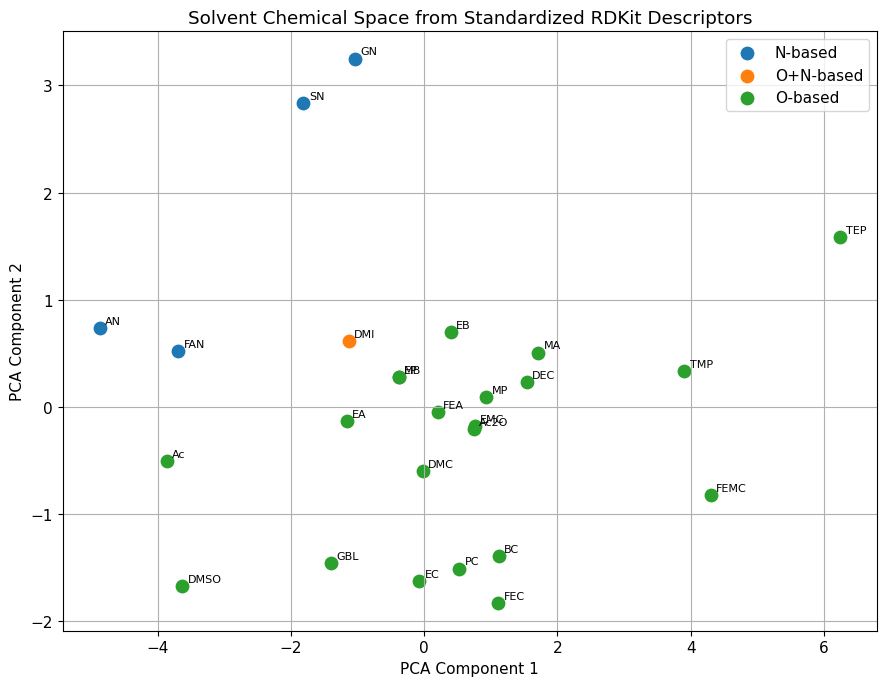

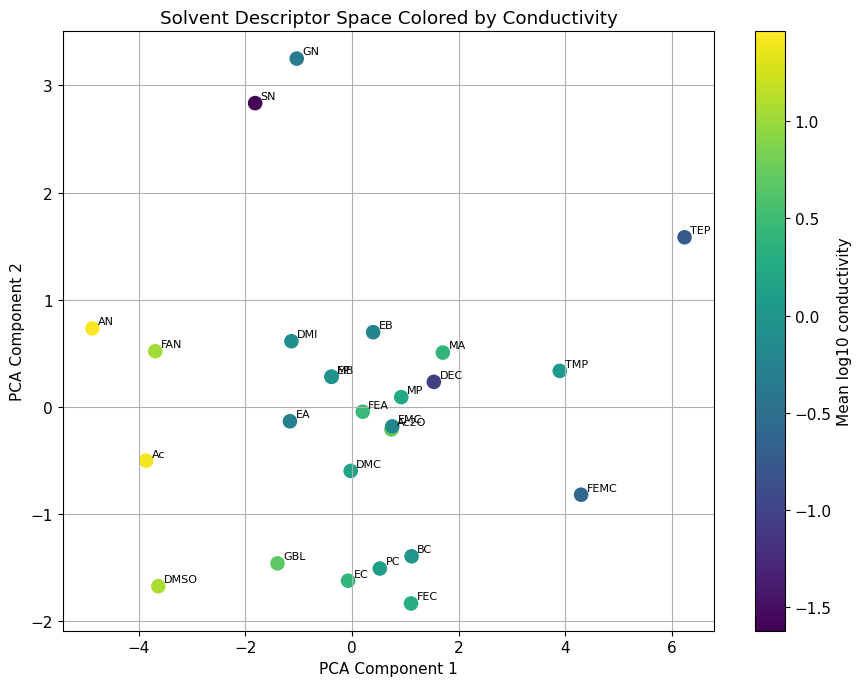

In [19]:
# ==========================================================
# Cell 18 — PCA of solvent descriptor chemical space
# ==========================================================

active_descriptors = [

    descriptor

    for descriptor
    in DESCRIPTOR_NAMES

    if (
        solvent_analysis[
            descriptor
        ].nunique() > 1

        and

        solvent_analysis[
            descriptor
        ].std(ddof=0) > 1e-12
    )
]


descriptor_scaler = StandardScaler()


X_solvent_scaled = (

    descriptor_scaler

    .fit_transform(

        solvent_analysis[
            active_descriptors
        ]
    )
)


pca = PCA(
    n_components=2,
    random_state=RANDOM_STATE
)


pca_coordinates = (

    pca.fit_transform(
        X_solvent_scaled
    )
)


solvent_pca = solvent_analysis.copy()

solvent_pca["PCA1"] = (
    pca_coordinates[:, 0]
)

solvent_pca["PCA2"] = (
    pca_coordinates[:, 1]
)


print(
    "PCA explained variance:"
)

print(
    pca.explained_variance_ratio_
)


display(

    solvent_pca[

        [
            "solvent",
            "solvent_family",
            "PCA1",
            "PCA2",
            "mean_log_conductivity"
        ]
    ]
)
plt.figure(
    figsize=(9, 7)
)


for family, subset in solvent_pca.groupby(
    "solvent_family"
):

    plt.scatter(

        subset["PCA1"],

        subset["PCA2"],

        s=80,

        label=family
    )


for _, row in solvent_pca.iterrows():

    plt.annotate(

        row["solvent"],

        (
            row["PCA1"],
            row["PCA2"]
        ),

        fontsize=8,

        xytext=(4, 3),

        textcoords="offset points"
    )


plt.xlabel(
    "PCA Component 1"
)

plt.ylabel(
    "PCA Component 2"
)

plt.title(
    "Solvent Chemical Space from Standardized RDKit Descriptors"
)

plt.legend()

plt.tight_layout()

plt.savefig(

    FIG_DIR /
    "notebook5_solvent_descriptor_pca_family.png",

    dpi=300
)

plt.show()

plt.figure(
    figsize=(9, 7)
)


scatter = plt.scatter(

    solvent_pca["PCA1"],

    solvent_pca["PCA2"],

    c=solvent_pca[
        "mean_log_conductivity"
    ],

    s=90
)


plt.colorbar(

    scatter,

    label="Mean log10 conductivity"
)


for _, row in solvent_pca.iterrows():

    plt.annotate(

        row["solvent"],

        (
            row["PCA1"],
            row["PCA2"]
        ),

        fontsize=8,

        xytext=(4, 3),

        textcoords="offset points"
    )


plt.xlabel(
    "PCA Component 1"
)

plt.ylabel(
    "PCA Component 2"
)

plt.title(
    "Solvent Descriptor Space Colored by Conductivity"
)

plt.tight_layout()

plt.savefig(

    FIG_DIR /
    "notebook5_solvent_descriptor_pca_conductivity.png",

    dpi=300
)

plt.show()

solvent,AN,Ac,Ac2O,BC,DEC,DMC,DMI,DMSO,EA,EB,...,FEMC,GBL,GN,MA,MB,MP,PC,SN,TEP,TMP
solvent,,,,,,,,,,,,,,,,,,,,,
AN,1.00,0.09,0.07,0.06,0.06,0.07,0.06,0.09,0.05,0.05,...,0.04,0.00,0.23,0.05,0.05,0.06,0.04,0.27,0.06,0.07
Ac,0.09,1.00,0.45,0.12,0.27,0.33,0.12,0.20,0.33,0.21,...,0.18,0.05,0.00,0.31,0.22,0.36,0.09,0.00,0.12,0.14
Ac2O,0.07,0.45,1.00,0.10,0.28,0.33,0.10,0.14,0.41,0.23,...,0.20,0.04,0.00,0.32,0.24,0.35,0.08,0.00,0.15,0.18
BC,0.06,0.12,0.10,1.00,0.13,0.10,0.24,0.12,0.08,0.07,...,0.06,0.17,0.00,0.08,0.07,0.08,0.41,0.00,0.08,0.10
DEC,0.06,0.27,0.28,0.13,1.00,0.35,0.13,0.12,0.59,0.50,...,0.32,0.04,0.05,0.27,0.32,0.24,0.07,0.05,0.30,0.21
DMC,0.07,0.33,0.33,0.10,0.35,1.00,0.10,0.14,0.26,0.23,...,0.43,0.04,0.05,0.39,0.37,0.44,0.08,0.00,0.15,0.25
DMI,0.06,0.12,0.10,0.24,0.13,0.10,1.00,0.12,0.08,0.07,...,0.06,0.17,0.00,0.08,0.07,0.08,0.19,0.00,0.08,0.10
DMSO,0.09,0.20,0.14,0.12,0.12,0.14,0.12,1.00,0.11,0.10,...,0.08,0.05,0.00,0.11,0.10,0.12,0.09,0.00,0.12,0.14
EA,0.05,0.33,0.41,0.08,0.59,0.26,0.08,0.11,1.00,0.48,...,0.26,0.04,0.04,0.32,0.30,0.29,0.07,0.05,0.29,0.20


,solvent,nearest_solvent,nearest_similarity,mean_similarity_to_all,chemical_isolation_score
7,DMSO,Ac,0.200000,0.094002,0.800000
6,DMI,BC,0.238095,0.096330,0.761905
0,AN,SN,0.272727,0.073414,0.727273
25,TMP,TEP,0.352941,0.141501,0.647059
24,TEP,TMP,0.352941,0.145540,0.647059
17,GBL,EC,0.368421,0.069903,0.631579
10,EC,GBL,0.368421,0.087175,0.631579
3,BC,PC,0.409091,0.113268,0.590909
13,FAN,SN,0.416667,0.064710,0.583333
21,MP,DMC,0.437500,0.183960,0.562500


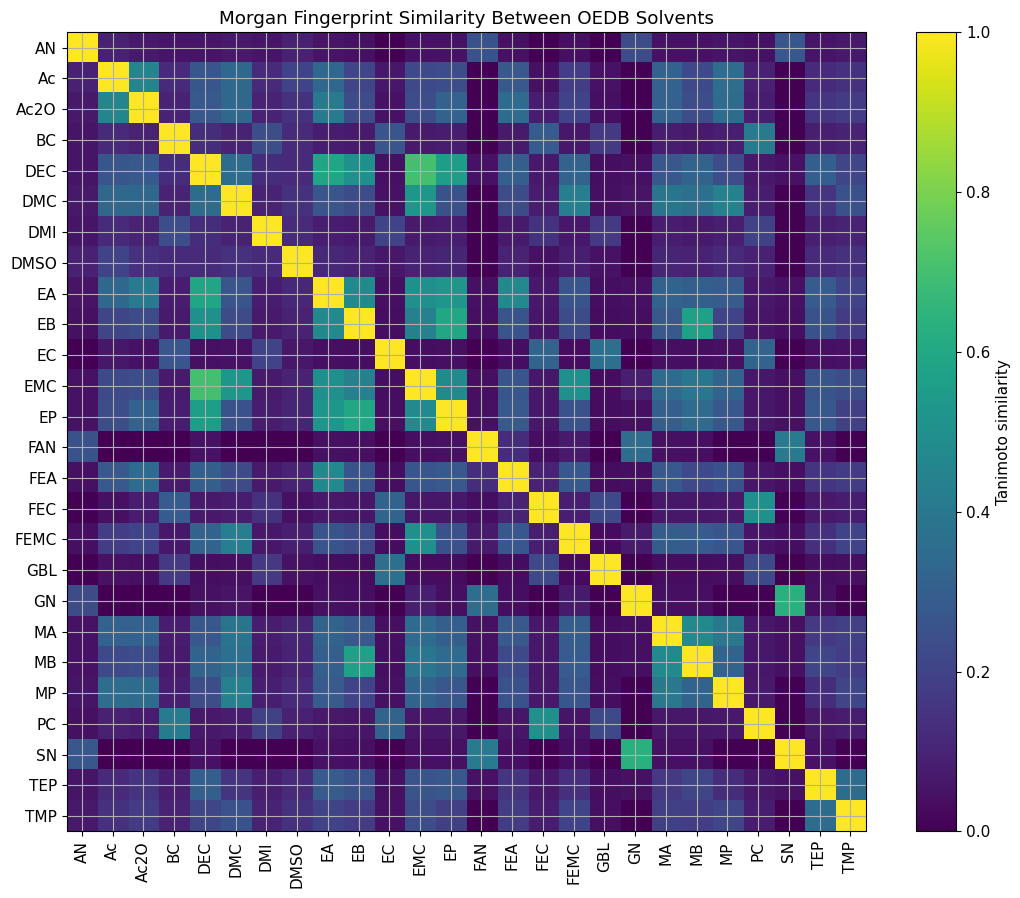

In [24]:
# ==========================================================
# Cell 19 — Morgan fingerprint similarity between solvents
# ==========================================================

morgan_generator = (

    rdFingerprintGenerator

    .GetMorganGenerator(

        radius=2,

        fpSize=1024
    )
)


solvent_fingerprints = []


for smiles in solvent_analysis[
    "solvent_smiles"
]:

    mol = Chem.MolFromSmiles(
        str(smiles)
    )

    if mol is None:

        raise ValueError(
            f"Invalid solvent SMILES: {smiles}"
        )

    fp = (
        morgan_generator

        .GetFingerprint(mol)
    )

    solvent_fingerprints.append(
        fp
    )


n_solvents = len(
    solvent_fingerprints
)


similarity_matrix = np.zeros(

    (
        n_solvents,
        n_solvents
    )
)


for i in range(
    n_solvents
):

    similarity_matrix[i, :] = (

        DataStructs

        .BulkTanimotoSimilarity(

            solvent_fingerprints[i],

            solvent_fingerprints
        )
    )


similarity_df = pd.DataFrame(

    similarity_matrix,

    index=solvent_analysis[
        "solvent"
    ],

    columns=solvent_analysis[
        "solvent"
    ]
)


display(
    similarity_df.round(2)
)
nearest_rows = []


for i in range(
    n_solvents
):

    similarities = (
        similarity_matrix[i]
        .copy()
    )

    similarities[i] = -1

    nearest_index = (
        np.argmax(
            similarities
        )
    )


    nearest_rows.append({

        "solvent":
            solvent_analysis.loc[
                i,
                "solvent"
            ],

        "nearest_solvent":
            solvent_analysis.loc[
                nearest_index,
                "solvent"
            ],

        "nearest_similarity":
            similarities[
                nearest_index
            ],

        "mean_similarity_to_all":
            (
                similarity_matrix[i].sum()
                - 1
            )
            /
            (
                n_solvents
                - 1
            )
    })


solvent_similarity = (

    pd.DataFrame(
        nearest_rows
    )

    .sort_values(
        "nearest_similarity"
    )
)


solvent_similarity[
    "chemical_isolation_score"
] = (

    1

    -

    solvent_similarity[
        "nearest_similarity"
    ]
)


display(
    solvent_similarity
)


solvent_similarity.to_csv(

    METRICS_DIR /
    "notebook5_solvent_similarity.csv",

    index=False
)

plt.figure(
    figsize=(11, 9)
)


im = plt.imshow(

    similarity_matrix,

    vmin=0,

    vmax=1,

    cmap="viridis"
)


plt.colorbar(

    im,

    label="Tanimoto similarity"
)


labels = solvent_analysis[
    "solvent"
].tolist()


plt.xticks(

    range(n_solvents),

    labels,

    rotation=90
)


plt.yticks(

    range(n_solvents),

    labels
)


plt.title(
    "Morgan Fingerprint Similarity Between OEDB Solvents"
)


plt.tight_layout()


plt.savefig(

    FIG_DIR /
    "notebook5_solvent_tanimoto_similarity.png",

    dpi=300
)


plt.show()

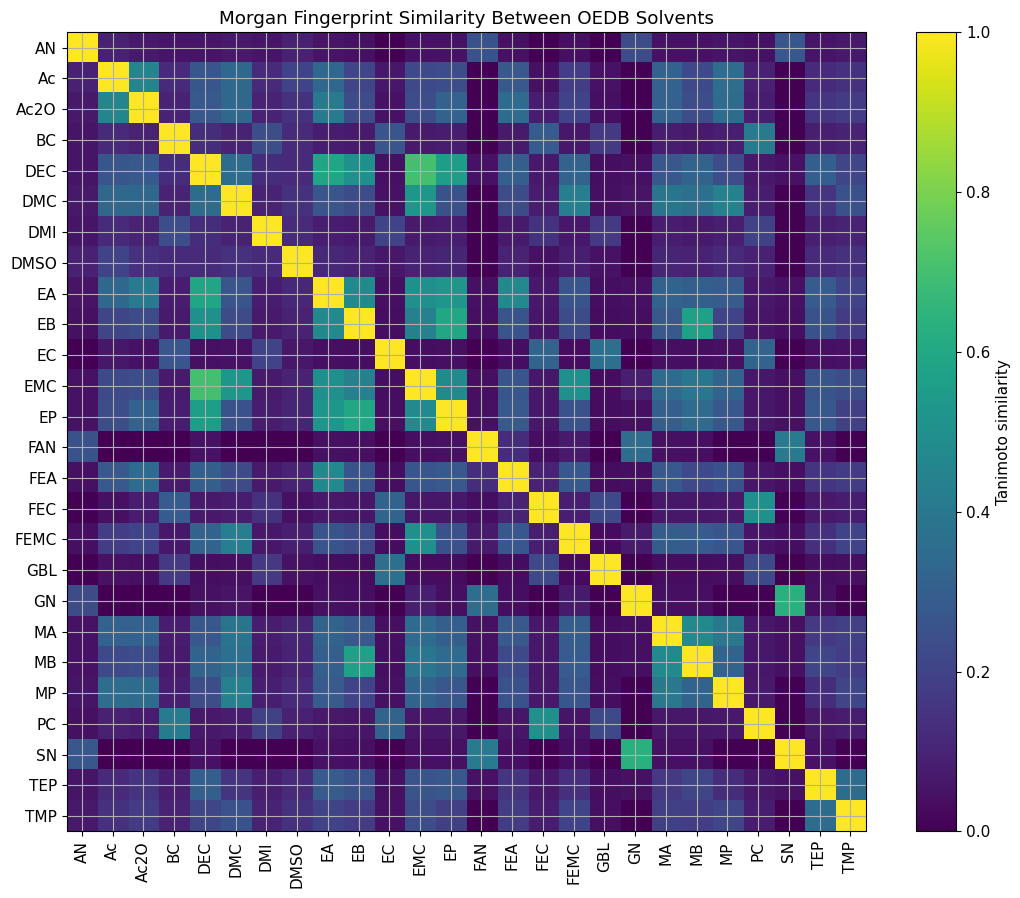

In [25]:
plt.figure(
    figsize=(11, 9)
)


im = plt.imshow(

    similarity_matrix,

    vmin=0,

    vmax=1,

    cmap="viridis"
)


plt.colorbar(

    im,

    label="Tanimoto similarity"
)


labels = solvent_analysis[
    "solvent"
].tolist()


plt.xticks(

    range(n_solvents),

    labels,

    rotation=90
)


plt.yticks(

    range(n_solvents),

    labels
)


plt.title(
    "Morgan Fingerprint Similarity Between OEDB Solvents"
)


plt.tight_layout()


plt.savefig(

    FIG_DIR /
    "notebook5_solvent_tanimoto_similarity.png",

    dpi=300
)


plt.show()

In [28]:
# ==========================================================
# Cell 20 — Solvent family physicochemical comparison
# ==========================================================

solvent_family_summary = (

    solvent_analysis

    .groupby(
        "solvent_family"
    )

    .agg(

        n_solvents=(
            "solvent",
            "nunique"
        ),

        median_mean_log_conductivity=(
            "mean_log_conductivity",
            "median"
        ),

        mean_mean_log_conductivity=(
            "mean_log_conductivity",
            "mean"
        ),

        median_log10_viscosity=(
            "mean_log10_viscosity",
            "median"
        ),

        median_cation_anion_coordination=(
            "mean_coord_cation_anion",
            "median"
        ),

        median_cation_solvent_coordination=(
            "mean_coord_cation_solvent",
            "median"
        )
    )

    .reset_index()
)


display(
    solvent_family_summary
)


solvent_family_summary.to_csv(

    METRICS_DIR /
    "notebook5_solvent_family_physicochemical_summary.csv",

    index=False
)

,solvent_family,n_solvents,median_mean_log_conductivity,mean_mean_log_conductivity,median_log10_viscosity,median_cation_anion_coordination,median_cation_solvent_coordination
0,N-based,4,0.345353,0.132848,0.850566,1.925584,4.285906
1,O+N-based,1,-0.103460,-0.103460,1.227966,2.084885,3.418386
2,O-based,21,0.101485,0.135251,0.903197,3.005445,5.667182


In [29]:
# ==========================================================
# Cell 21 — Integrated solvent diagnostic table
# ==========================================================

solvent_diagnostic = (

    solvent_pca

    .merge(

        solvent_similarity,

        on="solvent",

        how="left"
    )
)


solvent_diagnostic[
    "conductivity_rank"
] = (

    solvent_diagnostic[
        "mean_log_conductivity"
    ]

    .rank(
        ascending=False
    )
)


solvent_diagnostic[
    "chemical_isolation_rank"
] = (

    solvent_diagnostic[
        "chemical_isolation_score"
    ]

    .rank(
        ascending=False
    )
)


diagnostic_columns = [

    "solvent",

    "solvent_family",

    "is_cyclic",

    "mean_log_conductivity",

    "mean_log10_viscosity",

    "mean_coord_cation_anion",

    "mean_coord_cation_solvent",

    "nearest_solvent",

    "nearest_similarity",

    "chemical_isolation_score",

    "PCA1",

    "PCA2",

    "conductivity_rank",

    "chemical_isolation_rank",
]


display(

    solvent_diagnostic[

        diagnostic_columns

    ]

    .sort_values(
        "chemical_isolation_score",
        ascending=False
    )
)


solvent_diagnostic.to_csv(

    METRICS_DIR /
    "notebook5_integrated_solvent_diagnostics.csv",

    index=False
)

,solvent,solvent_family,is_cyclic,mean_log_conductivity,mean_log10_viscosity,mean_coord_cation_anion,mean_coord_cation_solvent,nearest_solvent,nearest_similarity,chemical_isolation_score,PCA1,PCA2,conductivity_rank,chemical_isolation_rank
7,DMSO,O-based,False,1.071558,0.592242,1.219385,4.038864,Ac,0.200000,0.800000,-3.632201,-1.671982,3.0,1.0
6,DMI,O+N-based,True,-0.103460,1.227966,2.084885,3.418386,BC,0.238095,0.761905,-1.135358,0.613562,18.0,2.0
0,AN,N-based,False,1.461275,0.013519,1.731468,4.318741,SN,0.272727,0.727273,-4.869566,0.732832,1.0,3.0
25,TMP,O-based,False,0.055371,1.119149,2.572776,8.950894,TEP,0.352941,0.647059,3.899546,0.336955,14.0,4.5
24,TEP,O-based,False,-0.763897,1.088542,3.940129,5.667182,TMP,0.352941,0.647059,6.240587,1.583176,24.0,4.5
10,EC,O-based,True,0.401987,1.142299,2.210126,9.470634,GBL,0.368421,0.631579,-0.072249,-1.620646,8.0,6.5
17,GBL,O-based,True,0.682198,0.903197,1.965362,6.785509,EC,0.368421,0.631579,-1.396407,-1.458960,6.0,6.5
3,BC,O-based,True,-0.017417,0.995460,3.602708,6.190919,PC,0.409091,0.590909,1.119425,-1.392951,15.0,8.0
13,FAN,N-based,False,1.037490,0.175433,3.230846,2.972997,SN,0.416667,0.583333,-3.688632,0.520449,4.0,9.0
21,MP,O-based,False,0.241570,0.906601,2.933439,4.205942,DMC,0.437500,0.562500,0.925489,0.092055,11.0,10.0


In [31]:
# ==========================================================
# Cell 22 — Model error vs chemical / physical diagnostics
# ==========================================================

NOTEBOOK4_ERROR_PATH = (

    METRICS_DIR /
    "notebook4_solvent_wise_error_best_model.csv"
)


if NOTEBOOK4_ERROR_PATH.exists():

    notebook4_error = pd.read_csv(
        NOTEBOOK4_ERROR_PATH
    )


    error_diagnostic = (

        solvent_diagnostic

        .merge(

            notebook4_error,

            on="solvent",

            how="inner",

            suffixes=(
                "",
                "_notebook4"
            )
        )
    )


    display(
        error_diagnostic.head()
    )


    error_variables = [

        "mean_log_conductivity",

        "mean_log10_viscosity",

        "mean_coord_cation_anion",

        "mean_coord_cation_solvent",

        "nearest_similarity",

        "chemical_isolation_score",
    ]


    error_association_rows = []


    for variable in error_variables:

        temp = (

            error_diagnostic[
                [
                    variable,
                    "MAE"
                ]
            ]

            .dropna()
        )


        if (
            len(temp) >= 5
            and
            temp[variable].nunique() > 1
        ):

            rho, p_value = spearmanr(

                temp[variable],

                temp["MAE"]
            )


            error_association_rows.append({

                "variable":
                    variable,

                "spearman_with_MAE":
                    rho,

                "p_value":
                    p_value,

                "n_solvents":
                    len(temp)
            })


    error_associations = (

        pd.DataFrame(
            error_association_rows
        )

        .sort_values(

            "spearman_with_MAE",

            key=lambda x: x.abs(),

            ascending=False
        )
    )


    print(
        "What chemical/physical factors are associated "
        "with prediction error?"
    )

    display(
        error_associations
    )


    error_diagnostic.to_csv(

        METRICS_DIR /
        "notebook5_error_chemistry_diagnostic.csv",

        index=False
    )


    error_associations.to_csv(

        METRICS_DIR /
        "notebook5_error_associations.csv",

        index=False
    )


else:

    print(
        "Notebook 4 solvent error file was not found:"
    )

    print(
        NOTEBOOK4_ERROR_PATH
    )

    print(
        "Run Notebook 4 first, then rerun this cell."
    )
    if NOTEBOOK4_ERROR_PATH.exists():

        plt.figure(
        figsize=(8, 6)
    )

    plt.scatter(

        error_diagnostic[
            "nearest_similarity"
        ],

        error_diagnostic[
            "MAE"
        ],

        s=70
    )


    for _, row in error_diagnostic.iterrows():

        plt.annotate(

            row["solvent"],

            (
                row[
                    "nearest_similarity"
                ],

                row[
                    "MAE"
                ]
            ),

            fontsize=8,

            xytext=(4, 3),

            textcoords="offset points"
        )


    plt.xlabel(
        "Nearest training-chemistry Tanimoto similarity"
    )

    plt.ylabel(
        "Solvent GroupKFold MAE (mS/cm)"
    )

    plt.title(
        "Does Chemical Isolation Relate to Prediction Error?"
    )

    plt.tight_layout()


    plt.savefig(

        FIG_DIR /
        "notebook5_error_vs_solvent_similarity.png",

        dpi=300
    )


    plt.show()

,solvent,solvent_smiles,mol_wt,exact_mol_wt,tpsa,num_h_acceptors,num_h_donors,num_rotatable_bonds,ring_count,heavy_atom_count,...,chemical_isolation_score,conductivity_rank,chemical_isolation_rank,solvent_family_notebook4,n_samples,MAE,RMSE,mean_actual,mean_predicted,mean_bias_actual_minus_pred
0,AN,CC#N,41.053,41.026549,23.79,1,0,0,0,3,...,0.727273,1.0,3.0,N-based,216,13.839322,20.275410,38.445499,29.037057,9.408442
1,Ac,CC(=O)C,58.080,58.041865,17.07,1,0,0,0,4,...,0.545455,2.0,11.5,O-based,216,13.488129,19.630303,34.234726,22.992504,11.242222
2,Ac2O,CC(=O)OC(=O)C,102.089,102.031694,43.37,3,0,0,0,7,...,0.545455,5.0,11.5,O-based,216,4.808220,6.509551,7.881364,3.168940,4.712425
3,BC,C[C@H]1[C@@H](OC(=O)O1)C,116.116,116.047344,35.53,3,0,0,1,8,...,0.590909,15.0,8.0,O-based,216,0.874281,1.120176,1.432196,2.179301,-0.747105
4,DEC,CCOC(=O)OCC,118.132,118.062994,35.53,3,0,2,0,8,...,0.294118,25.0,25.5,O-based,214,0.768521,1.074943,0.229712,0.988690,-0.758978


What chemical/physical factors are associated with prediction error?


,variable,spearman_with_MAE,p_value,n_solvents
0,mean_log_conductivity,0.805812,6.779413e-07,26
2,mean_coord_cation_anion,-0.664957,2.105934e-04,26
5,chemical_isolation_score,0.576470,2.052970e-03,26
4,nearest_similarity,-0.576470,2.052970e-03,26
1,mean_log10_viscosity,-0.292991,1.463363e-01,26
3,mean_coord_cation_solvent,-0.116581,5.706097e-01,26


In [32]:
# ==========================================================
# Cell 23 — Notebook 5 completion
# ==========================================================

print("Notebook 5 analysis complete.")

print("\nMajor outputs generated:")

outputs = [

    "Dataset coverage and missingness",

    "Property distribution statistics",

    "Main-factor effect sizes",

    "Global Pearson/Spearman dependencies",

    "Conditional chemistry-dependent correlations",

    "Concentration-response analysis",

    "OEDB structural-space property maps",

    "Unique solvent and anion descriptor tables",

    "Descriptor redundancy analysis",

    "Descriptor-property association analysis",

    "Descriptor stability across cation/anion contexts",

    "Solvent descriptor PCA chemical space",

    "Morgan/Tanimoto solvent similarity analysis",

    "O-based vs N-based physicochemical comparison",

    "Integrated solvent diagnostic table",

    "Chemistry vs Notebook 4 prediction-error analysis",
]


for i, output in enumerate(
    outputs,
    start=1
):

    print(
        f"{i}. {output}"
    )

Notebook 5 analysis complete.

Major outputs generated:
1. Dataset coverage and missingness
2. Property distribution statistics
3. Main-factor effect sizes
4. Global Pearson/Spearman dependencies
5. Conditional chemistry-dependent correlations
6. Concentration-response analysis
7. OEDB structural-space property maps
8. Unique solvent and anion descriptor tables
9. Descriptor redundancy analysis
10. Descriptor-property association analysis
11. Descriptor stability across cation/anion contexts
12. Solvent descriptor PCA chemical space
13. Morgan/Tanimoto solvent similarity analysis
14. O-based vs N-based physicochemical comparison
15. Integrated solvent diagnostic table
16. Chemistry vs Notebook 4 prediction-error analysis
